In [1]:
%load_ext autoreload
%autoreload 2
# %matplotlib widget
%matplotlib inline

import os
import math
import sys
import torch
import matplotlib
import matplotlib.pyplot as plt

if not '../src' in sys.path:
    sys.path.append('../src')

from dataset import MuonDataset
from mappers import CustomMapper
from propagation import HighlandPropagator
from constants import *

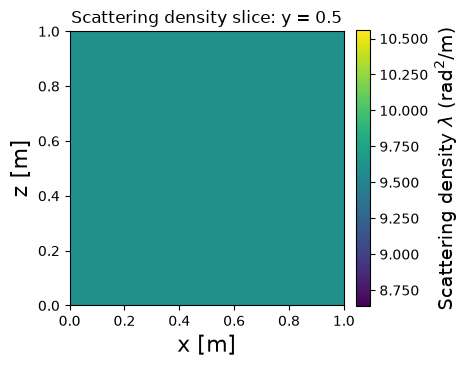

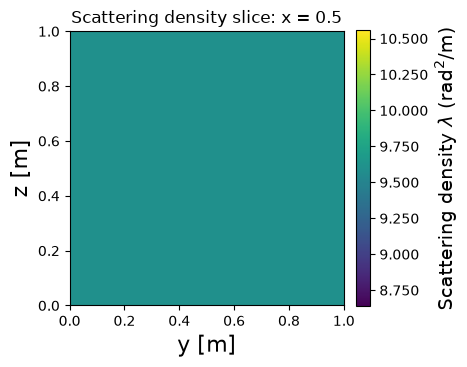

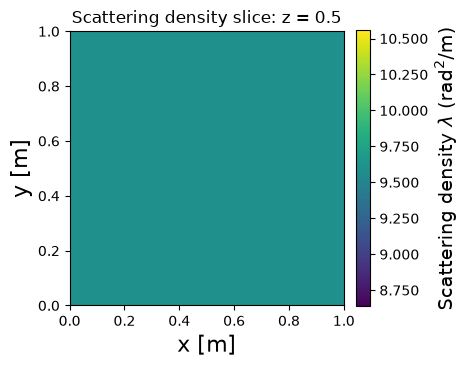

In [28]:
# 1. Define physical log-bounds (air vs core)
# Ensure these are positive physical lambda values (e.g., 1/X0), NOT -1 and +1
lambda_min = min(1/X0s['Air'], 1/X0s['Fe'])
lambda_max = max(1/X0s['Air'], 1/X0s['Fe'])

air_lam_log = math.log10(1/X0s['Air'])
core_lam_log = math.log10(1/X0s['Fe'])

radius =  0.6
center = torch.tensor([0., 0., 0.])
transition_width = 0.1  # Make it a clean, visible boundary

def func(x):
    """
    Returns a normalized value between -1 and +1, 
    representing the position between air_lam_log and core_lam_log.
    """
    r = torch.norm(x - center, dim=-1, keepdim=True)
    signed_dist = radius - r
    weight = torch.sigmoid(signed_dist / transition_width) # 0 to 1
    
    # Map weight [0, 1] to log-density space between air and core
    lam_log = air_lam_log + (core_lam_log - air_lam_log) * weight
    
    # Normalize lam_log back to [-1, 1] so BaseDensityMapper.process() can un-normalize it correctly!
    lam_normalized = 2 * (lam_log - air_lam_log) / (core_lam_log - air_lam_log) - 1
    return lam_normalized

def func(x):
    lam_log = torch.ones((x.shape[0],1),device=x.device) * math.log10(1. / X0s['Ca'])
    lam_normalized = 2 * (lam_log - air_lam_log) / (core_lam_log - air_lam_log) - 1
    return lam_normalized

mapper = CustomMapper(
    xlow = [0.,0.,0.],  # Adjust to your volume coordinate bounds
    xhigh = [1, 1, 1],
    ylow = 1/X0s['Air'],   # Pass actual positive lower physical bound
    yhigh = 1/X0s['Fe'],   # Pass actual positive upper physical bound
    func = func,
)

fig = mapper.plot_slice(
    direction = 'y',
    value = 0.5,
    low = [0,0],
    high = [1,1],
    batch_size = 5000,
    points = 20,
    show_materials = False,
)
fig = mapper.plot_slice(
    direction = 'x',
    value = 0.5,
    low = [0,0],
    high = [1,1],
    batch_size = 5000,
    points = 20,
    show_materials = False,
)
fig = mapper.plot_slice(
    direction = 'z',
    value = 0.5,
    low = [0,0],
    high = [1,1],
    batch_size = 5000,
    points = 20,
    show_materials = False,
)

In [30]:
import torch
import math

def generate_incoming_muons(
    num_muons, 
    x_range=(0.0, 1.0), 
    y_range=(0.0, 1.0), 
    z_top=1.0, 
    mean_momentum=4.0,   # Mean momentum scale for the exponential distribution (e.g., in GeV/c)
    max_theta_deg=30.0,  # Max spread angle from the straight-down (z-axis) direction
    device='cpu'
):
    """
    Generates initial positions on the top face, downward directions, 
    and momenta following an inverse exponential spectrum.
    """
    # 1. Initial Positions (x, y uniform on the top face at z = z_top)
    x = torch.rand(num_muons, device=device) * (x_range[1] - x_range[0]) + x_range[0]
    y = torch.rand(num_muons, device=device) * (y_range[1] - y_range[0]) + y_range[0]
    z = torch.full((num_muons,), z_top, device=device)
    positions = torch.stack([x, y, z], dim=-1) # Shape: (N, 3)

    # 2. Directions (Downward cone or hemisphere)
    # If you want them mostly pointing straight down (-z) with a slight angular spread:
    max_theta = math.radians(max_theta_deg)
    # Uniform sampling in cosine of theta for a cone, or full hemisphere
    u_theta = torch.rand(num_muons, device=device)
    theta = torch.acos(1.0 - u_theta * (1.0 - math.cos(max_theta))) # Polar angle from -z
    phi = torch.rand(num_muons, device=device) * 2 * math.pi       # Azimuthal angle
    
    # Convert spherical to Cartesian components (pointing downwards in -z)
    dx = torch.sin(theta) * torch.cos(phi)
    dy = torch.sin(theta) * torch.sin(phi)
    dz = -torch.cos(theta) # Strictly negative Z (downward)
    
    directions = torch.stack([dx, dy, dz], dim=-1) # Shape: (N, 3)

    # 3. Momentum (Inverse exponential spectrum via Inverse Transform Sampling)
    # Exponential PDF: f(p) = (1/beta) * exp(-p / beta)
    # Inverse CDF: p = -beta * ln(1 - u)
    u_mom = torch.rand(num_muons, device=device)
    u_mom = torch.clamp(u_mom, min=1e-7, max=1.0 - 1e-7) # Prevent log(0)
    momentum = -mean_momentum * torch.log(1.0 - u_mom) # Shape: (N,) or (N, 1)
    
    return positions, directions, momentum.unsqueeze(-1)

ri,di,pi = generate_incoming_muons(
    num_muons = int(1e6),
    x_range=(0.0, 1.0), 
    y_range=(0.0, 1.0), 
    z_top=1.0, 
    mean_momentum=4.0,
    max_theta_deg=30.0,
    device='cpu',
)


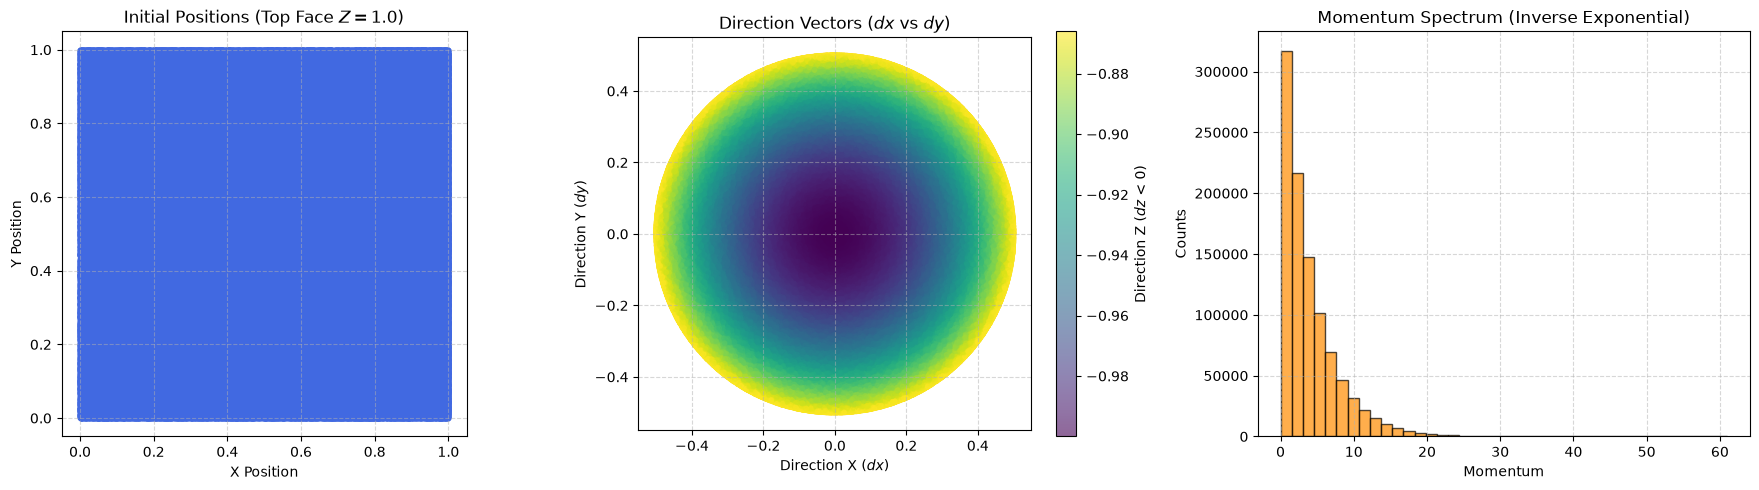

In [31]:
# Convert to numpy for matplotlib
ri_np = ri.numpy()
di_np = di.numpy()
pi_np = pi.squeeze(-1).numpy()

# Create 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Positions Plot (Top Face X-Y distribution)
axes[0].scatter(ri_np[:, 0], ri_np[:, 1], alpha=0.6, s=10, color='royalblue')
axes[0].set_title('Initial Positions (Top Face $Z=1.0$)')
axes[0].set_xlabel('X Position')
axes[0].set_ylabel('Y Position')
axes[0].set_aspect('equal')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Directions Plot (dx vs dy angular spread, colored by dz)
sc = axes[1].scatter(di_np[:, 0], di_np[:, 1], c=di_np[:, 2], cmap='viridis', alpha=0.6, s=10)
axes[1].set_title('Direction Vectors ($dx$ vs $dy$)')
axes[1].set_xlabel('Direction X ($dx$)')
axes[1].set_ylabel('Direction Y ($dy$)')
cbar = plt.colorbar(sc, ax=axes[1])
cbar.set_label('Direction Z ($dz$ < 0)')
axes[1].set_aspect('equal')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Momentum Spectrum Plot (Exponential Decay Histogram)
axes[2].hist(pi_np, bins=40, color='darkorange', edgecolor='black', alpha=0.7)
axes[2].set_title('Momentum Spectrum (Inverse Exponential)')
axes[2].set_xlabel('Momentum')
axes[2].set_ylabel('Counts')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [32]:
propagator = HighlandPropagator(
    step_size = 0.01,
)
propagator.low = torch.tensor([0.,0.,0.])
propagator.high = torch.tensor([1.,1.,1.])

with torch.no_grad():
    rf, df, pf = propagator.propagate(
        mapper = mapper,
        ri = ri,
        di = di,
        pi = pi,
    )

Propagation : [====================================================================================================] 100%
Propagation done in 1665 steps, max distance 1.583


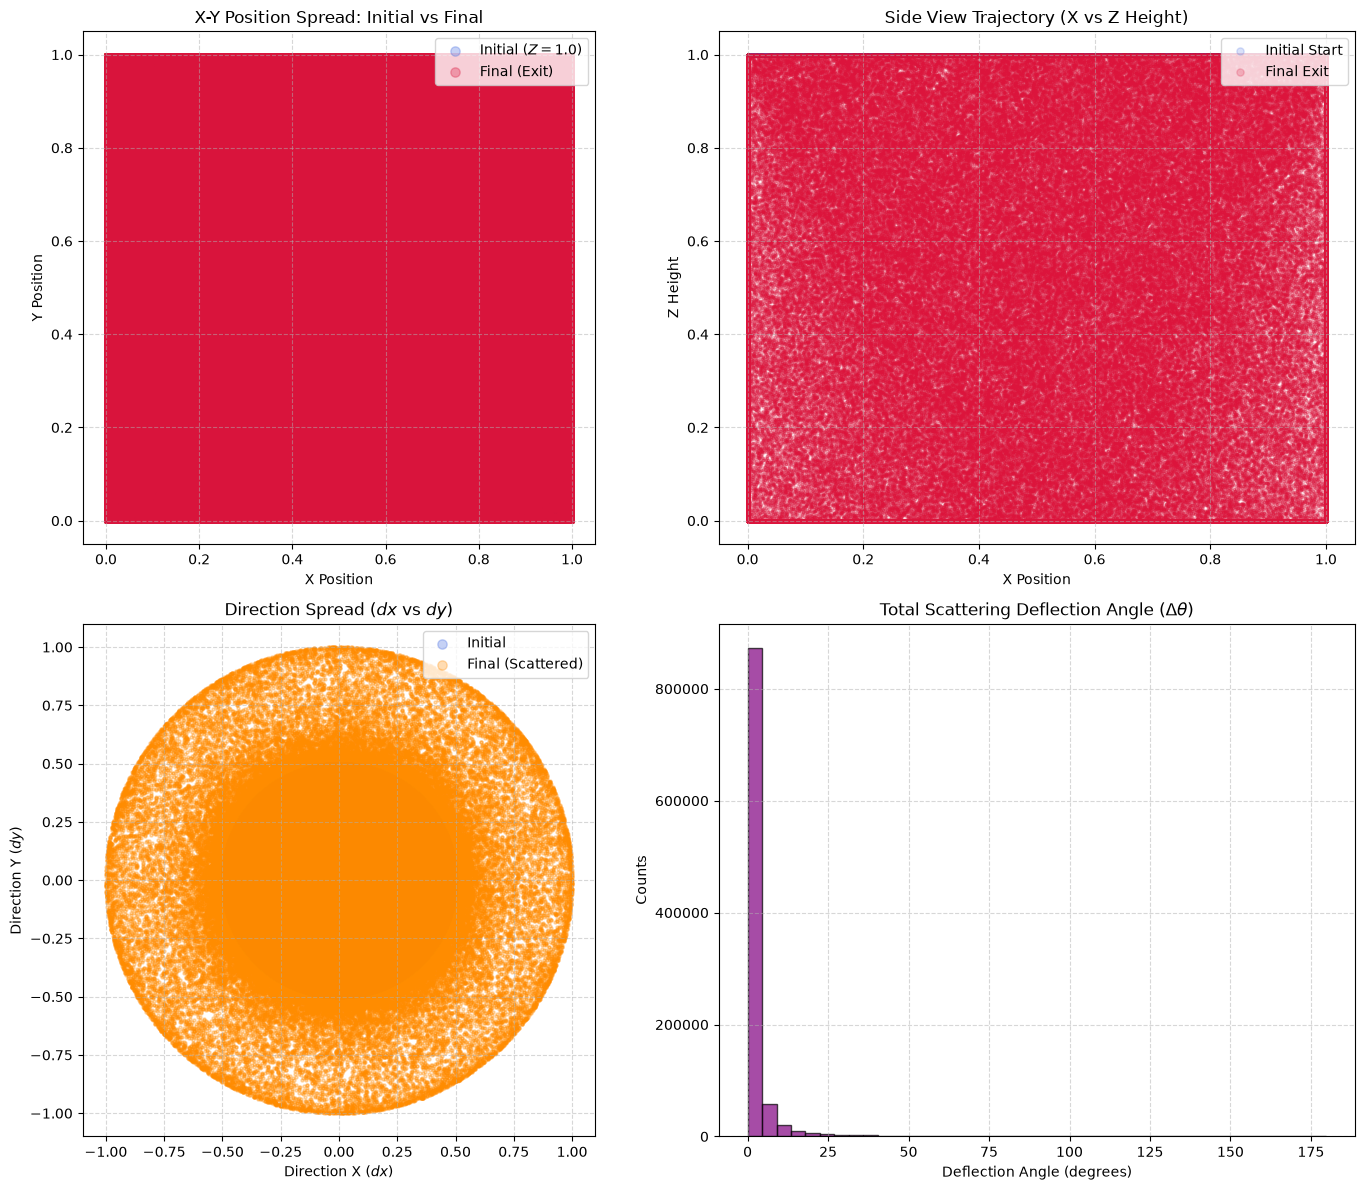

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Convert tensors to numpy arrays
ri_np = ri.detach().cpu().numpy()
di_np = di.detach().cpu().numpy()
rf_np = rf.detach().cpu().numpy()
df_np = df.detach().cpu().numpy()

# Create a 2x2 multi-panel figure for comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# --- Plot 1: X-Y Position Comparison ---
axes[0, 0].scatter(ri_np[:, 0], ri_np[:, 1], alpha=0.3, s=5, c='royalblue', label='Initial ($Z=1.0$)')
axes[0, 0].scatter(rf_np[:, 0], rf_np[:, 1], alpha=0.3, s=5, c='crimson', label='Final (Exit)')
axes[0, 0].set_title(r'X-Y Position Spread: Initial vs Final')
axes[0, 0].set_xlabel('X Position')
axes[0, 0].set_ylabel('Y Position')
axes[0, 0].set_aspect('equal')
axes[0, 0].legend(loc='upper right', markerscale=3)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: Side View Trajectories (X vs Z) ---
axes[0, 1].scatter(ri_np[:, 0], ri_np[:, 2], alpha=0.2, s=3, c='royalblue', label='Initial Start')
axes[0, 1].scatter(rf_np[:, 0], rf_np[:, 2], alpha=0.2, s=3, c='crimson', label='Final Exit')
axes[0, 1].set_title(r'Side View Trajectory (X vs Z Height)')
axes[0, 1].set_xlabel('X Position')
axes[0, 1].set_ylabel('Z Height')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend(loc='upper right', markerscale=3)

# --- Plot 3: Direction Spread ($dx$ vs $dy$) ---
axes[1, 0].scatter(di_np[:, 0], di_np[:, 1], alpha=0.3, s=5, c='royalblue', label='Initial')
axes[1, 0].scatter(df_np[:, 0], df_np[:, 1], alpha=0.3, s=5, c='darkorange', label='Final (Scattered)')
axes[1, 0].set_title(r'Direction Spread ($dx$ vs $dy$)')
axes[1, 0].set_xlabel('Direction X ($dx$)')
axes[1, 0].set_ylabel('Direction Y ($dy$)')
axes[1, 0].set_aspect('equal')
axes[1, 0].legend(loc='upper right', markerscale=3)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 4: Angular Deflection Histogram ---
dot_prods = np.sum(di_np * df_np, axis=-1)
dot_prods = np.clip(dot_prods, -1.0, 1.0)
scattering_angles_deg = np.degrees(np.arccos(dot_prods))

axes[1, 1].hist(scattering_angles_deg, bins=40, color='purple', edgecolor='black', alpha=0.7)
axes[1, 1].set_title(r'Total Scattering Deflection Angle ($\Delta \theta$)')
axes[1, 1].set_xlabel('Deflection Angle (degrees)')
axes[1, 1].set_ylabel('Counts')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [34]:
def selection(ri,rf,di,df):
    distance_mask =  (ri-rf).norm(dim=-1) > 0.05
    angle = torch.rad2deg(
        torch.acos(
            (di*df).sum(dim=-1)
        )
    )
    angle_mask = torch.logical_and(
        ~torch.isnan(angle),
        angle < 80.,
    )
    mask = torch.logical_and(distance_mask,angle_mask)
    return mask
    
dataset = MuonDataset(
    ri = ri,
    di = di,
    pi = pi,
    rf = rf,
    df = df,
    selection = selection,
)

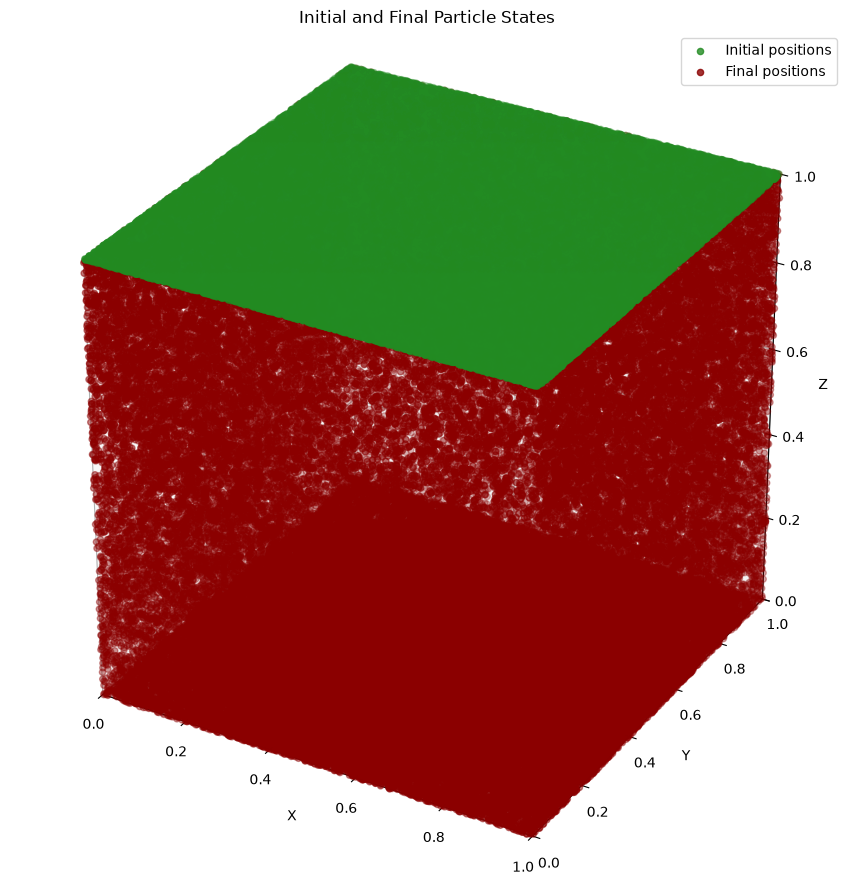

In [35]:
fig = dataset.plot_3d(N=100000)
plt.show()

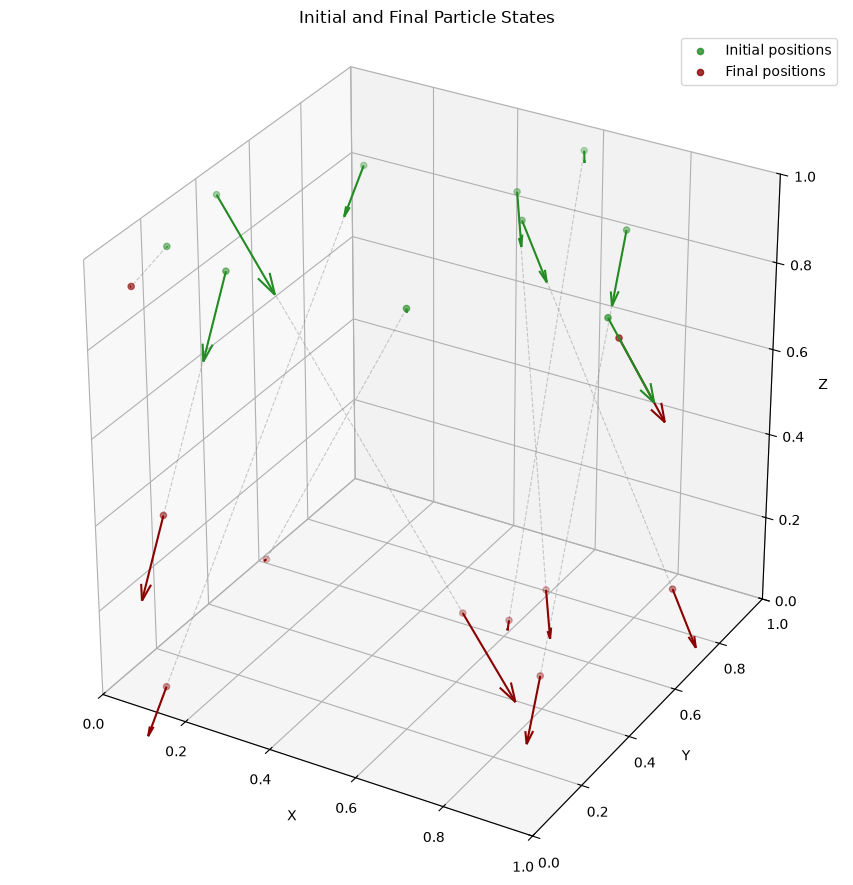

In [36]:
fig = dataset.plot_3d(N=10,show_direction=True,show_path=True,arrow_scale=0.1)
plt.show()

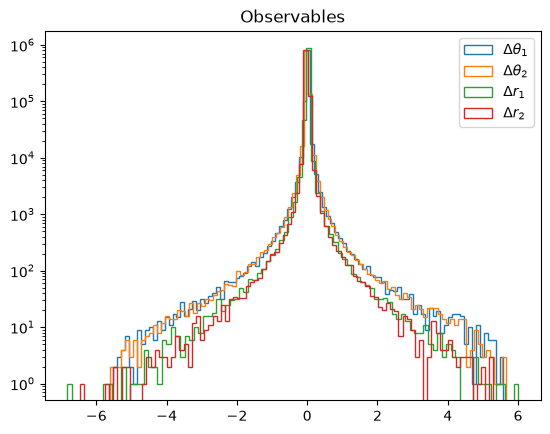

In [37]:
fig = dataset.plot_observables(log=True)
plt.show()

In [38]:
dataset.save(
    # data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_test.npy',
    # momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_test.npy',
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_uniform.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_uniform.npy',
    overwrite = True,
)

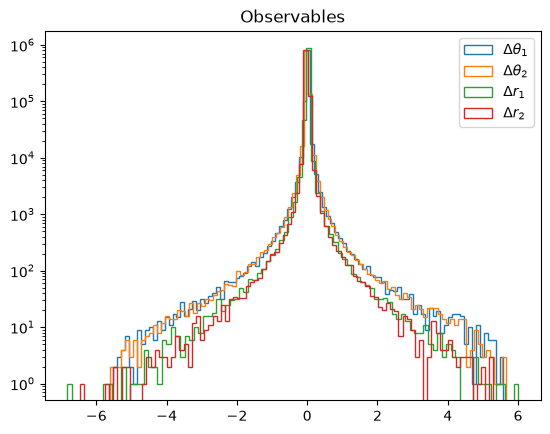

In [39]:
dataset_loaded = MuonDataset.from_data_file(
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_uniform.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_uniform.npy',
    selection = selection,
)

fig = dataset_loaded.plot_observables(log=True)
plt.show()